<a href="https://colab.research.google.com/github/TKcodes-bit/Stock-Price-Forecasting-Using-Time-Series-Analysis/blob/main/Stock_Price_Forecasting_Using_Time_Series_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stock Price Forecasting Using Time-Series Analysis

## Task 1: Time-Series Preprocessing and Exploratory Analysis

**Objective:** To explore historical stock market data and develop
a machine learning model to predict the next trading day's
closing price of Apple Inc. (AAPL).

# 1. Data Source and Collection

## 1.1 Dataset Description

The dataset selected for this project is the **S&P 500 Stock Data**, obtained from Kaggle.

The dataset contains historical daily stock market observations for companies listed in the S&P 500 index. It provides information on stock prices and trading activity over time, making it suitable for time-series analysis and forecasting.

For this study, we will focus specifically on **Apple Inc. (AAPL)** to investigate historical stock price movements and develop a machine learning model capable of predicting the next trading day's closing price.

## 1.2 Dataset Source

- **Dataset Name:** S&P 500 Stock Data
- **Platform:** Kaggle
- **Dataset Author:** Cam Nugent
- **Source:** https://www.kaggle.com/datasets/camnugent/sandp500
- **File:** all_stocks_5yr.csv
- **Selected Company:** Apple Inc. (AAPL)

## 1.3 Dataset Variables

The original dataset contains the following variables:

| Variable | Description |
|---|---|
| Date | Date of the stock market observation |
| Open | Stock opening price |
| High | Highest stock price recorded during the trading day |
| Low | Lowest stock price recorded during the trading day |
| Close | Stock closing price |
| Volume | Number of shares traded during the day |
| Name | Stock ticker symbol identifying the company |

## 1.4 Research Objective

The primary objective is to investigate the historical behaviour of Apple's stock prices and determine whether historical price movements, trading volume, lagged observations and moving averages can help predict its next trading day's closing price.

# 2. Dataset Storage and Google Drive Integration

The downloaded dataset will be stored in Google Drive to provide persistent access throughout the analysis and modelling stages.

Google Drive will serve as the central storage location for the original dataset, processed datasets, visualizations and model outputs.

This also helps maintain an organized and reproducible workflow.

In [ ]:

from google.colab import drive, files
import os
import shutil

# Mount Google Drive
drive.mount('/content/drive')

# Create project directory
project_dir = '/content/drive/MyDrive/Stock_Price_Forecasting'

os.makedirs(project_dir, exist_ok=True)

# Create subdirectories
data_dir = os.path.join(project_dir, 'data')
outputs_dir = os.path.join(project_dir, 'outputs')

os.makedirs(data_dir, exist_ok=True)
os.makedirs(outputs_dir, exist_ok=True)

# Upload dataset from computer
uploaded = files.upload()

# Move uploaded dataset to Google Drive
for filename in uploaded.keys():
    if filename.endswith('.csv'):
        destination = os.path.join(data_dir, filename)
        shutil.copy2(filename, destination)
        print(f"Dataset successfully saved to: {destination}")

print("\nGoogle Drive setup completed!")


Mounted at /content/drive


Saving all_stocks_5yr.csv to all_stocks_5yr.csv
Dataset successfully saved to: /content/drive/MyDrive/Stock_Price_Forecasting/data/all_stocks_5yr.csv

Google Drive setup completed!


# 3. Data Analysis and Exploratory Data Analysis







### 3.1 Introduction

Exploratory Data Analysis (EDA) is performed to understand the structure, characteristics and underlying patterns within the selected dataset before applying machine learning techniques.

In this section, the original stock market dataset will be examined to identify its dimensions, data types, temporal coverage, missing observations, duplicate records and statistical characteristics.

The analysis will focus on Apple's historical stock market observations and will establish the foundation for subsequent time-series preprocessing, feature engineering and predictive modelling.

The following analysis will be conducted:

1. Dataset loading and inspection.
2. Data filtering and preparation.
3. Examination of the time range and observation frequency.
4. Missing value and duplicate analysis.
5. Descriptive statistical analysis.
6. Distribution analysis of numerical variables.
7. Temporal trend and pattern analysis.

###3.2 Importing the required libraries
Before analysing the dataset, we need to import the Python libraries.

We will use:
Library	Purpose
Pandas	Data manipulation and analysis
NumPy	Numerical computations
Matplotlib	Data visualization
Seaborn	Statistical visualizations
OS	File and directory management
Warnings	Managing unnecessary warnings

In [ ]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File and directory management
import os

# Warning management
import warnings

# Suppress unnecessary warnings
warnings.filterwarnings('ignore')

# Visualization settings
sns.set_theme(style="whitegrid")

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

# Reproducibility
np.random.seed(42)

print("All required libraries imported successfully!")


All required libraries imported successfully!


### 3.3 Loading the Dataset

The original CSV file is loaded from the Google Drive project directory using Pandas.

At this stage, the dataset will be loaded without modifying or removing any observations. This allows for the inspection the original data before making preprocessing decisions.

In [ ]:

# Define dataset path
dataset_path = os.path.join(
    data_dir,
    'all_stocks_5yr.csv'
)

# Load original dataset
df = pd.read_csv(dataset_path)

# Display confirmation
print("Dataset loaded successfully!")

# Display first five observations
display(df.head())


Dataset loaded successfully!


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


### 3.4 Dataset Structure and Initial Inspection

The first stage of exploratory data analysis involves examining the overall structure of the original dataset.

This includes determining the total number of observations and variables, identifying their respective data types, and inspecting sample records.

The purpose is to understand how the dataset is organized and identify any potential data quality issues before performing further preprocessing.

The original dataset is retained at this stage to preserve its integrity during the initial inspection.

In [ ]:

# Determine the number of rows and columns
rows, columns = df.shape

print("DATASET DIMENSIONS")
print("-------------------")
print(f"Total observations: {rows:,}")
print(f"Total variables: {columns}")

print("\nCOLUMN NAMES")
print("------------")
print(df.columns.tolist())


DATASET DIMENSIONS
-------------------
Total observations: 619,040
Total variables: 7

COLUMN NAMES
------------
['date', 'open', 'high', 'low', 'close', 'volume', 'Name']


Data types and information

In [ ]:

# Display dataset information
print("DATASET INFORMATION")
print("-------------------")

df.info()


DATASET INFORMATION
-------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619040 non-null  object 
 1   open    619029 non-null  float64
 2   high    619032 non-null  float64
 3   low     619032 non-null  float64
 4   close   619040 non-null  float64
 5   volume  619040 non-null  int64  
 6   Name    619040 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB


Preview the dataset

In [ ]:

# Display first 10 observations
display(df.head(10))

# Display last 5 observations
display(df.tail())


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL
5,2013-02-15,13.93,14.61,13.93,14.50,15628000,AAL
6,2013-02-19,14.33,14.56,14.08,14.26,11354400,AAL
7,2013-02-20,14.17,14.26,13.15,13.33,14725200,AAL
8,2013-02-21,13.62,13.95,12.90,13.37,11922100,AAL
9,2013-02-22,13.57,13.60,13.21,13.57,6071400,AAL


,date,open,high,low,close,volume,Name
619035,2018-02-01,76.84,78.27,76.69,77.82,2982259,ZTS
619036,2018-02-02,77.53,78.12,76.73,76.78,2595187,ZTS
619037,2018-02-05,76.64,76.92,73.18,73.83,2962031,ZTS
619038,2018-02-06,72.74,74.56,72.13,73.27,4924323,ZTS
619039,2018-02-07,72.70,75.00,72.69,73.86,4534912,ZTS


Check unique companies

In [ ]:

# Count unique stock tickers
unique_companies = df["Name"].nunique()

print("Number of unique companies:", unique_companies)

print("\nFirst 20 stock tickers:")
print(df["Name"].unique()[:20])


Number of unique companies: 505

First 20 stock tickers:
['AAL' 'AAPL' 'AAP' 'ABBV' 'ABC' 'ABT' 'ACN' 'ADBE' 'ADI' 'ADM' 'ADP'
 'ADSK' 'ADS' 'AEE' 'AEP' 'AES' 'AET' 'AFL' 'AGN' 'AIG']


###  Dataset Overview

The project uses the *S&P 500 Stock Data* dataset obtained from Kaggle. The dataset contains **619,040 observations and 7 variables**, covering stock-market records for **505 companies**.

The dataset contains daily stock-market information, including the opening price, highest price, lowest price, closing price, and trading volume for each company.

The variables are:

| Variable | Description |
|---|---|
| `date` | Date of the stock-market observation |
| `open` | Opening stock price |
| `high` | Highest stock price during the trading day |
| `low` | Lowest stock price during the trading day |
| `close` | Closing stock price |
| `volume` | Number of shares traded |
| `Name` | Stock ticker identifying the company |

The dataset is suitable for time-series forecasting because it contains dated observations and measurable financial variables. For this project, the analysis will focus on **Apple Inc. (AAPL)** to develop a model that predicts the next trading day's closing price using historical stock information.

###  Missing Values Assessment

An initial inspection revealed missing values in the `open`, `high`, and `low` columns. The `date`, `close`, `volume`, and `Name` columns contain no missing values.

The next stage examines the number and distribution of missing values across the dataset. This is important because missing observations may affect the reliability of the analysis and subsequent forecasting models.

In [ ]:

# Check missing values in each column

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': (missing_values / len(df)) * 100
})

display(missing_summary)


,Missing Values,Percentage (%)
date,0,0.000000
open,11,0.001777
high,8,0.001292
low,8,0.001292
close,0,0.000000
volume,0,0.000000
Name,0,0.000000


### Date Conversion and Company Selection

The original dataset contains stock-market observations for 505 companies. To maintain a focused forecasting objective, this project selects Apple Inc. (AAPL) for further analysis.

The date variable is converted into datetime format to support chronological sorting and time-series operations. The filtered observations are then sorted from the earliest to the latest trading date.

This project uses historical Apple stock information to investigate whether market variables, previous closing prices, and moving averages can help predict the next trading day's closing price.

In [ ]:

# Convert the date column to datetime format
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Filter the dataset to include Apple Inc. (AAPL)
apple_df = df[df['Name'] == 'AAPL'].copy()

# Sort observations chronologically
apple_df = apple_df.sort_values('date').reset_index(drop=True)

# Display the results
print("APPLE STOCK DATA")
print("----------------")
print("Total observations:", len(apple_df))
print("First trading date:", apple_df['date'].min())
print("Last trading date:", apple_df['date'].max())

print("\nFirst five observations:")
display(apple_df.head())

print("\nLast five observations:")
display(apple_df.tail())


APPLE STOCK DATA
----------------
Total observations: 1259
First trading date: 2013-02-08 00:00:00
Last trading date: 2018-02-07 00:00:00

First five observations:


,date,open,high,low,close,volume,Name
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL



Last five observations:


,date,open,high,low,close,volume,Name
1254,2018-02-01,167.165,168.62,166.7600,167.78,47230787,AAPL
1255,2018-02-02,166.000,166.80,160.1000,160.50,86593825,AAPL
1256,2018-02-05,159.100,163.88,156.0000,156.49,72738522,AAPL
1257,2018-02-06,154.830,163.72,154.0000,163.03,68243838,AAPL
1258,2018-02-07,163.085,163.40,159.0685,159.54,51608580,AAPL


 ###  Data Quality Assessment for Apple Stock Data

After filtering the original dataset, a focused data-quality assessment is performed on the Apple stock observations.

This assessment checks for missing values, duplicate trading dates, and gaps between consecutive observations. Since stock markets do not operate on weekends and certain public holidays, gaps in calendar dates are expected and should not automatically be treated as missing observations.

These checks help establish whether the selected dataset is sufficiently consistent for further exploratory analysis and forecasting.

In [ ]:

# Check missing values in the Apple dataset
print("MISSING VALUES IN AAPL")
print("----------------------")
print(apple_df.isnull().sum())

# Check duplicate dates
print("\nDUPLICATE TRADING DATES")
print("----------------------")
print("Number of duplicate dates:",
      apple_df['date'].duplicated().sum())

# Examine differences between consecutive dates
date_gaps = apple_df['date'].diff().dt.days

print("\nDATE GAP DISTRIBUTION")
print("---------------------")
print(date_gaps.value_counts().sort_index())

print("\nLargest gap between consecutive observations:",
      date_gaps.max(), "calendar days")


MISSING VALUES IN AAPL
----------------------
date      0
open      0
high      0
low       0
close     0
volume    0
Name      0
dtype: int64

DUPLICATE TRADING DATES
----------------------
Number of duplicate dates: 0

DATE GAP DISTRIBUTION
---------------------
date
1.0    986
2.0     11
3.0    227
4.0     34
Name: count, dtype: int64

Largest gap between consecutive observations: 4.0 calendar days


### Data Quality Findings

The Apple dataset contains 1,259 observations with no missing values across the seven columns and no duplicate trading dates.

The differences between consecutive observations range from one to four calendar days. These gaps are consistent with the non-continuous operation of stock markets, including weekends and market holidays.

No missing-value imputation or duplicate removal was necessary for the selected AAPL dataset. The original observations were retained for subsequent analysis.

###  Descriptive Statistical Analysis

Descriptive statistics are used to examine the numerical characteristics of the selected Apple stock dataset.

The analysis considers the opening, highest, lowest, and closing prices, alongside trading volume. Measures such as the mean, median, standard deviation, minimum, and maximum help describe the distribution and variability of the financial variables.

This provides an initial understanding of Apple's historical market behaviour before investigating relationships and patterns through visualizations.

In [ ]:

# Select numerical columns
numeric_columns = ['open', 'high', 'low', 'close', 'volume']

# Generate descriptive statistics
descriptive_stats = apple_df[numeric_columns].describe().T

# Add the median
descriptive_stats['median'] = apple_df[numeric_columns].median()

# Display results
display(descriptive_stats.round(2))


,count,mean,std,min,25%,50%,75%,max,median
open,1259.0,109.06,30.55,55.42,84.65,108.97,127.34,1.793700e+02,108.97
high,1259.0,109.95,30.69,57.09,85.33,110.03,128.10,1.801000e+02,110.03
low,1259.0,108.14,30.38,55.01,84.25,108.05,126.29,1.782500e+02,108.05
close,1259.0,109.07,30.56,55.79,84.83,109.01,127.12,1.792600e+02,109.01
volume,1259.0,54047899.74,33468353.34,11475922.00,29694376.50,45668931.00,68708720.00,2.668336e+08,45668931.00


###EDA

###EXPLORATORY DATA ANALYSIS

#### 2.1 Historical Closing Price Trend

**Analytical Question 1: How did Apple's closing stock price change between February 2013 and February 2018?**

This analysis examines the historical movement of Apple's daily closing stock price over the selected five-year period.

A time-series line chart is used to visualize changes in the closing price, identify general trends, and highlight periods of noticeable price fluctuations.

Understanding historical price behaviour provides an initial foundation for identifying patterns that may be useful in predicting future closing prices.

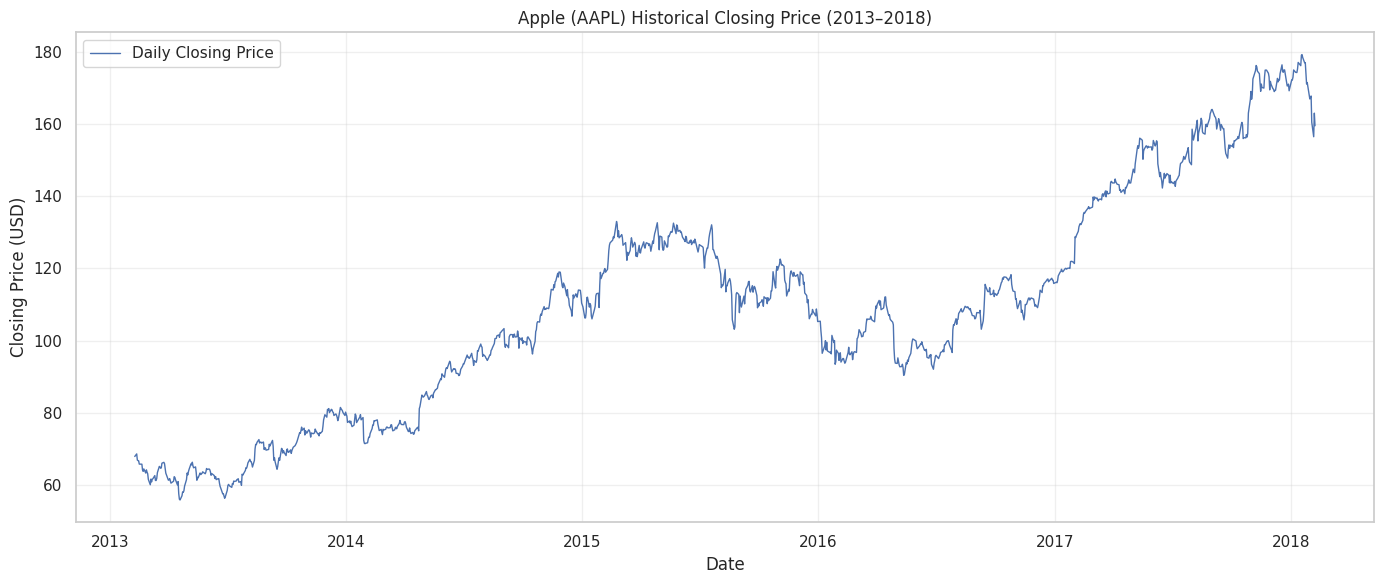

In [ ]:

# Plot Apple's historical closing price

plt.figure(figsize=(14, 6))

plt.plot(
    apple_df['date'],
    apple_df['close'],
    label='Daily Closing Price',
    linewidth=1
)

plt.title("Apple (AAPL) Historical Closing Price (2013–2018)")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### 2.2 Moving Average Analysis

**Analytical Question 2: How do short-term and long-term moving averages reveal trends in Apple's stock prices?**

Moving averages are used to smooth daily price fluctuations and identify underlying trends in historical stock prices.

This analysis calculates the 20-day and 50-day simple moving averages of Apple's closing prices. The 20-day moving average captures shorter-term price movements, while the 50-day moving average provides a broader view of the stock's price direction.

Comparing these moving averages with the actual closing price helps identify periods of upward and downward momentum.

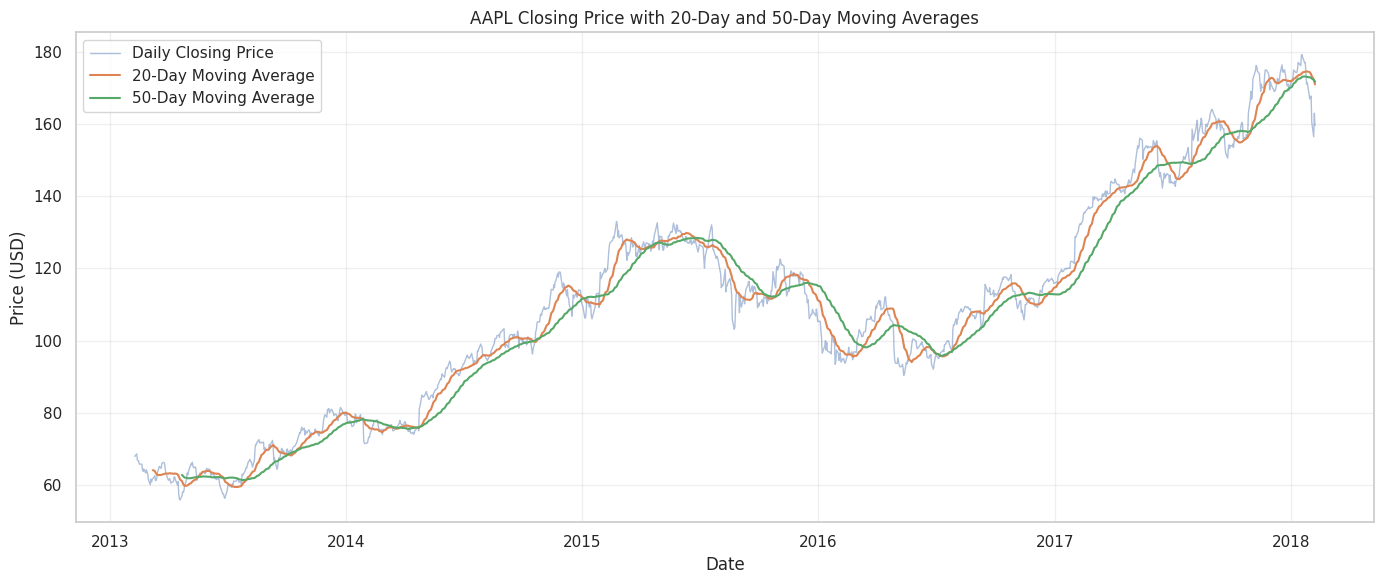

In [ ]:

# Calculate moving averages
apple_df['MA_20'] = apple_df['close'].rolling(window=20).mean()
apple_df['MA_50'] = apple_df['close'].rolling(window=50).mean()

# Plot closing price and moving averages
plt.figure(figsize=(14, 6))

plt.plot(
    apple_df['date'],
    apple_df['close'],
    label='Daily Closing Price',
    alpha=0.45,
    linewidth=1
)

plt.plot(
    apple_df['date'],
    apple_df['MA_20'],
    label='20-Day Moving Average',
    linewidth=1.5
)

plt.plot(
    apple_df['date'],
    apple_df['MA_50'],
    label='50-Day Moving Average',
    linewidth=1.5
)

plt.title("AAPL Closing Price with 20-Day and 50-Day Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### 2.3 Lagged Closing Price Analysis

**Analytical Question 3: How strongly is Apple's current closing price related to its previous trading days' closing prices?**

Historical stock prices may contain temporal dependencies, where previous observations are associated with subsequent prices.

To investigate this relationship, lagged features are created using the closing prices from one and five trading days earlier.

The analysis compares the current closing price with these historical values using correlation coefficients and scatter plots. This helps establish whether previous price observations contain useful information about subsequent stock-price behaviour.

In [ ]:

# Create lagged closing price features
apple_df['close_lag_1'] = apple_df['close'].shift(1)
apple_df['close_lag_5'] = apple_df['close'].shift(5)

# Calculate correlations
lag_correlations = apple_df[
    ['close', 'close_lag_1', 'close_lag_5']
].corr()

print("CORRELATION BETWEEN CURRENT AND PREVIOUS CLOSING PRICES")
display(lag_correlations.round(4))


CORRELATION BETWEEN CURRENT AND PREVIOUS CLOSING PRICES


,close,close_lag_1,close_lag_5
close,1.0000,0.9987,0.9934
close_lag_1,0.9987,1.0000,0.9948
close_lag_5,0.9934,0.9948,1.0000


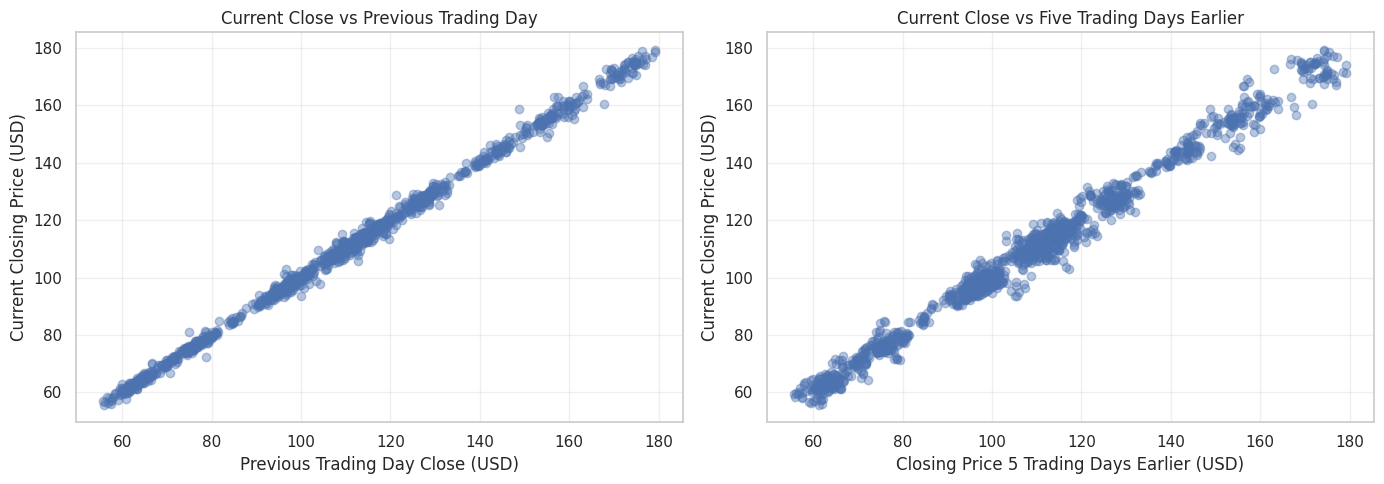

In [ ]:

# Visualize relationships between current and lagged prices

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# One-day lag
axes[0].scatter(
    apple_df['close_lag_1'],
    apple_df['close'],
    alpha=0.4
)
axes[0].set_title('Current Close vs Previous Trading Day')
axes[0].set_xlabel('Previous Trading Day Close (USD)')
axes[0].set_ylabel('Current Closing Price (USD)')
axes[0].grid(alpha=0.3)

# Five-day lag
axes[1].scatter(
    apple_df['close_lag_5'],
    apple_df['close'],
    alpha=0.4
)
axes[1].set_title('Current Close vs Five Trading Days Earlier')
axes[1].set_xlabel('Closing Price 5 Trading Days Earlier (USD)')
axes[1].set_ylabel('Current Closing Price (USD)')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# Calculate exact Pearson correlations
correlation_lag_1 = apple_df['close'].corr(apple_df['close_lag_1'])
correlation_lag_5 = apple_df['close'].corr(apple_df['close_lag_5'])

print(f"Lag-1 Pearson correlation: {correlation_lag_1:.4f}")
print(f"Lag-5 Pearson correlation: {correlation_lag_5:.4f}")

print(f"\nLag-1 R-squared: {correlation_lag_1**2:.4f}")
print(f"Lag-5 R-squared: {correlation_lag_5**2:.4f}")


Lag-1 Pearson correlation: 0.9987
Lag-5 Pearson correlation: 0.9934

Lag-1 R-squared: 0.9973
Lag-5 R-squared: 0.9869


#### 2.4 Trading Volume and Daily Price Movements

**Analytical Question 4: Is Apple's trading volume associated with the magnitude of its daily stock-price movements?**

Trading volume represents the number of shares exchanged during a trading day. Daily percentage returns measure the relative change in the closing price between consecutive trading days.

This analysis investigates whether days with higher trading activity are associated with larger price movements.

Daily percentage returns and their absolute values are calculated. The absolute returns are then compared with trading volume using Pearson correlation and a scatter plot.

This helps establish whether trading activity is linearly associated with the magnitude of Apple's daily price fluctuations.

In [ ]:

# Calculate daily percentage returns
apple_df['daily_return_pct'] = apple_df['close'].pct_change() * 100

# Calculate the absolute daily returns
apple_df['absolute_return_pct'] = apple_df['daily_return_pct'].abs()

# Calculate correlation between trading volume and absolute returns
volume_return_corr = apple_df[
    ['volume', 'absolute_return_pct']
].corr()

print("TRADING VOLUME AND DAILY PRICE MOVEMENTS")
print("----------------------------------------")
display(volume_return_corr.round(4))

print(
    "\nCorrelation between volume and absolute daily returns:",
    round(volume_return_corr.loc['volume', 'absolute_return_pct'], 4)
)


TRADING VOLUME AND DAILY PRICE MOVEMENTS
----------------------------------------


,volume,absolute_return_pct
volume,1.0000,0.4715
absolute_return_pct,0.4715,1.0000



Correlation between volume and absolute daily returns: 0.4715


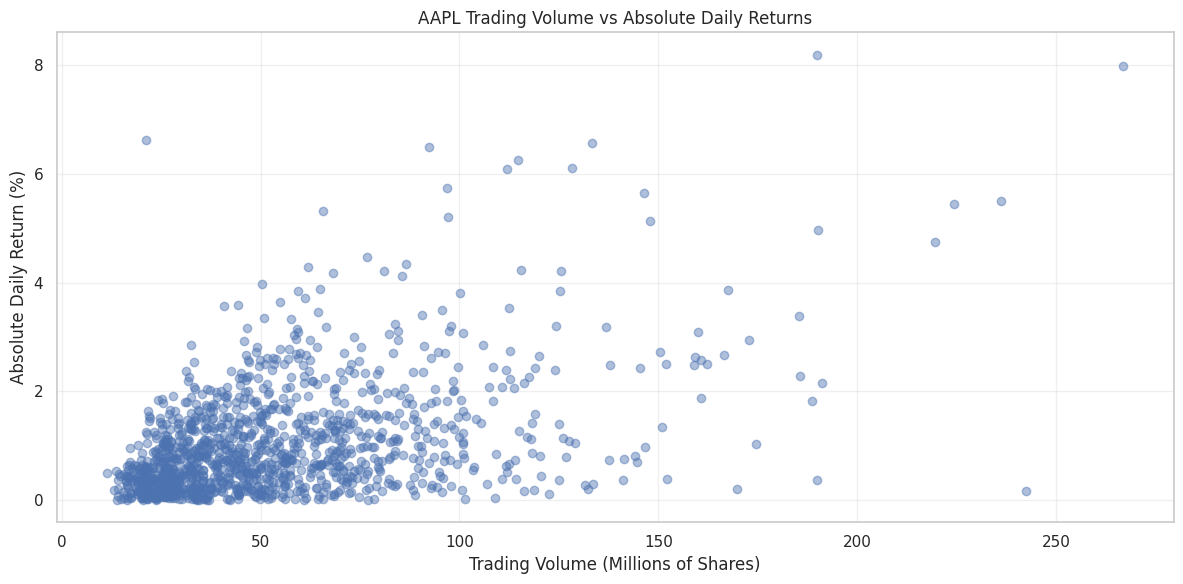

In [ ]:

# Scatter plot: Trading volume vs absolute daily returns

plt.figure(figsize=(12, 6))

plt.scatter(
    apple_df['volume'] / 1_000_000,
    apple_df['absolute_return_pct'],
    alpha=0.45
)

plt.title("AAPL Trading Volume vs Absolute Daily Returns")
plt.xlabel("Trading Volume (Millions of Shares)")
plt.ylabel("Absolute Daily Return (%)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


#### 2.5 Historical Stock Price Volatility Analysis

**Analytical Question 5: How did Apple's stock price volatility change between 2013 and 2018?**

Stock-price volatility describes the degree of variation in stock returns over time.

This analysis uses daily percentage returns and a 20-day rolling standard deviation to examine changes in Apple's historical price volatility.

The rolling standard deviation provides a moving measure of return variability, helping identify periods of relatively stable market behaviour and periods of increased price fluctuations.

Understanding historical volatility is important because stock prices do not exhibit constant levels of variability throughout time.

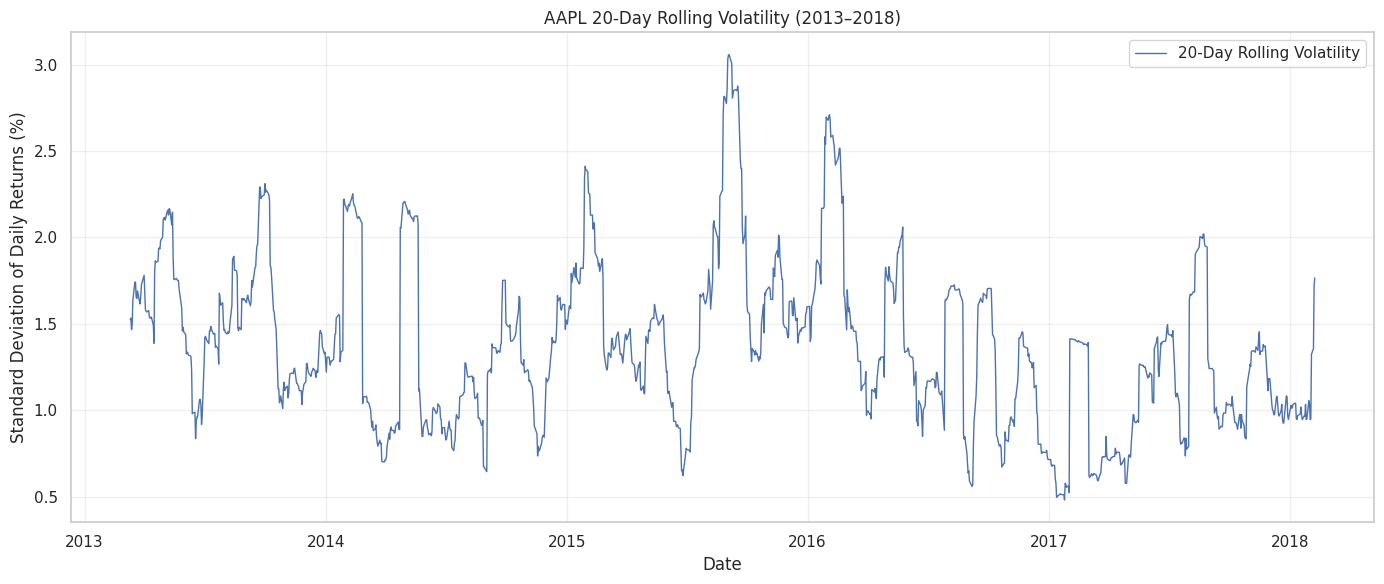

In [ ]:

# Calculate 20-day rolling volatility
apple_df['rolling_volatility'] = (
    apple_df['daily_return_pct']
    .rolling(window=20)
    .std()
)

# Plot rolling volatility
plt.figure(figsize=(14, 6))

plt.plot(
    apple_df['date'],
    apple_df['rolling_volatility'],
    label='20-Day Rolling Volatility',
    linewidth=1
)

plt.title("AAPL 20-Day Rolling Volatility (2013–2018)")
plt.xlabel("Date")
plt.ylabel("Standard Deviation of Daily Returns (%)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 3. Predictive Modelling



### 3.1 Feature Engineering and Target Variable Creation

The predictive modelling stage aims to develop machine learning models capable of forecasting Apple's next trading day's closing stock price.

Feature engineering is performed to extract useful information from the historical stock observations. The selected features include opening, highest, lowest and closing prices, trading volume, historical closing prices, moving averages, daily percentage returns and rolling volatility.

The target variable is created by shifting the closing-price column by one observation. This ensures that each row contains information from the current trading day while the target represents the closing price of the next trading day.

This approach maintains the chronological relationship between the predictor variables and the target while avoiding the use of future information during feature construction.

In [ ]:

# Define the features for the forecasting model

feature_columns = [
    'open',
    'high',
    'low',
    'close',
    'volume',
    'MA_20',
    'MA_50',
    'close_lag_1',
    'close_lag_5',
    'daily_return_pct',
    'rolling_volatility'
]

# Create a separate modelling dataset
model_df = apple_df.copy()

# Create the next trading day's closing price as the target
model_df['target_next_close'] = model_df['close'].shift(-1)

# Record the date corresponding to the target
model_df['target_date'] = model_df['date'].shift(-1)

# Remove rows with missing feature or target values
model_df = model_df.dropna(
    subset=feature_columns + ['target_next_close']
).reset_index(drop=True)

# Display modelling dataset information
print("MODELLING DATASET")
print("-----------------")
print("Total observations:", len(model_df))
print("Number of features:", len(feature_columns))
print("Target variable: target_next_close")

print("\nFeature columns:")
print(feature_columns)

print("\nFirst five modelling observations:")
display(
    model_df[
        ['date', 'target_date'] +
        feature_columns +
        ['target_next_close']
    ].head()
)

print("\nMissing values:")
print(model_df[feature_columns + ['target_next_close']].isnull().sum().sum())


MODELLING DATASET
-----------------
Total observations: 1209
Number of features: 11
Target variable: target_next_close

Feature columns:
['open', 'high', 'low', 'close', 'volume', 'MA_20', 'MA_50', 'close_lag_1', 'close_lag_5', 'daily_return_pct', 'rolling_volatility']

First five modelling observations:


,date,target_date,open,high,low,close,volume,MA_20,MA_50,close_lag_1,close_lag_5,daily_return_pct,rolling_volatility,target_next_close
0,2013-04-22,2013-04-23,56.0914,57.4571,55.8964,56.9528,107338322,61.030070,62.747386,55.7899,59.9785,2.084427,1.860943,58.0185
1,2013-04-23,2013-04-24,57.7128,58.3401,56.9728,58.0185,160760747,60.619715,62.550672,56.9528,60.8914,1.871199,1.936086,57.9231
2,2013-04-24,2013-04-25,56.2199,59.3214,56.0714,57.9231,242387530,60.222045,62.337906,58.0185,57.5428,-0.164430,1.938908,58.3399
3,2013-04-25,2013-04-26,58.7464,59.1342,58.1428,58.3399,95984896,59.909900,62.167848,57.9231,56.0071,0.719575,1.934090,59.6007
4,2013-04-26,2013-04-29,58.5442,59.8241,58.3214,59.6007,191006032,59.728080,62.025550,58.3399,55.7899,2.161128,1.982190,61.4457



Missing values:
0


### 3.2 Chronological Train, Validation and Test Split

The modelling dataset is divided into training, validation and testing subsets using a chronological splitting strategy.

Seventy percent of the observations are allocated to training, fifteen percent to validation, and the remaining fifteen percent to testing.

The training set is used to fit the machine learning models. The validation set supports model comparison and hyperparameter tuning, while the testing set provides an independent evaluation of the final selected model.

Unlike random splitting, chronological splitting preserves the temporal order of stock-market observations. This reduces the risk of future information influencing the training process and provides a more realistic evaluation of forecasting performance.

In [ ]:

# Define features and target
X = model_df[feature_columns]
y = model_df['target_next_close']

# Calculate chronological split boundaries
train_end = int(len(model_df) * 0.70)
validation_end = int(len(model_df) * 0.85)

# Split without shuffling
X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:validation_end]
y_val = y.iloc[train_end:validation_end]

X_test = X.iloc[validation_end:]
y_test = y.iloc[validation_end:]

# Display dataset sizes
print("CHRONOLOGICAL DATA SPLIT")
print("------------------------")

print(f"Training observations:   {len(X_train)}")
print(f"Validation observations: {len(X_val)}")
print(f"Testing observations:    {len(X_test)}")

print("\nDATE RANGES")
print("-----------")

print(
    "Training:",
    model_df.iloc[0]['date'].date(),
    "to",
    model_df.iloc[train_end - 1]['date'].date()
)

print(
    "Validation:",
    model_df.iloc[train_end]['date'].date(),
    "to",
    model_df.iloc[validation_end - 1]['date'].date()
)

print(
    "Testing:",
    model_df.iloc[validation_end]['date'].date(),
    "to",
    model_df.iloc[-1]['date'].date()
)

print("\nFEATURE SHAPES")
print("--------------")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)


CHRONOLOGICAL DATA SPLIT
------------------------
Training observations:   846
Validation observations: 181
Testing observations:    182

DATE RANGES
-----------
Training: 2013-04-22 to 2016-08-26
Validation: 2016-08-29 to 2017-05-17
Testing: 2017-05-18 to 2018-02-06

FEATURE SHAPES
--------------
X_train: (846, 11)
X_val: (181, 11)
X_test: (182, 11)


###  Baseline Model: Linear Regression

Linear Regression is selected as the baseline predictive model. It establishes an initial benchmark for forecasting Apple's next trading day's closing price using the engineered historical features.

The model learns linear relationships between the predictor variables and the target closing price.

Performance is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²). These metrics provide complementary measures of prediction error and explanatory performance.

The baseline results will be used to assess whether more complex machine learning models and hyperparameter tuning provide improvements.

In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Initialize the baseline model
linear_model = LinearRegression()

# Train using training data
linear_model.fit(X_train, y_train)

# Generate validation predictions
linear_val_predictions = linear_model.predict(X_val)

# Evaluate model performance
linear_mae = mean_absolute_error(y_val, linear_val_predictions)

linear_rmse = np.sqrt(
    mean_squared_error(y_val, linear_val_predictions)
)

linear_r2 = r2_score(y_val, linear_val_predictions)

# Display results
baseline_results = pd.DataFrame({
    'Model': ['Linear Regression'],
    'MAE': [linear_mae],
    'RMSE': [linear_rmse],
    'R2': [linear_r2]
})

print("BASELINE MODEL: LINEAR REGRESSION")
display(baseline_results.round(4))


BASELINE MODEL: LINEAR REGRESSION


,Model,MAE,RMSE,R2
0,Linear Regression,0.9405,1.3967,0.9908


### Experiment 2: Random Forest Regression

Random Forest Regression is introduced to determine whether an ensemble of decision trees can capture non-linear relationships between historical stock market features and Apple's next trading day's closing price.

Unlike Linear Regression, Random Forest does not assume a linear relationship between input variables and the target. It combines predictions from multiple decision trees to produce a final prediction.

The model is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R². Its validation performance is compared with the Linear Regression baseline to determine whether the more complex model provides an improvement.

In [ ]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

rf_val_predictions = random_forest_model.predict(X_val)

rf_mae = mean_absolute_error(y_val, rf_val_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_val_predictions))
rf_r2 = r2_score(y_val, rf_val_predictions)

rf_results = pd.DataFrame({
    'Model': ['Random Forest'],
    'MAE': [rf_mae],
    'RMSE': [rf_rmse],
    'R2': [rf_r2]
})

print("EXPERIMENT 2: RANDOM FOREST REGRESSION")
display(rf_results.round(4))


EXPERIMENT 2: RANDOM FOREST REGRESSION


,Model,MAE,RMSE,R2
0,Random Forest,5.9135,9.2443,0.5964


### Experiment 3: Random Forest Hyperparameter Tuning

A second Random Forest experiment is conducted to investigate the effect of hyperparameter choices on forecasting performance.

The experiment increases the number of trees and adjusts tree depth and minimum sample requirements. The objective is to determine whether a different model configuration improves validation performance and reduces prediction errors.

The same training and validation datasets and evaluation metrics are retained to ensure a fair comparison.

In [ ]:

rf_tuned_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

rf_tuned_model.fit(X_train, y_train)

rf_tuned_predictions = rf_tuned_model.predict(X_val)

rf_tuned_results = pd.DataFrame({
    'Model': ['Random Forest Tuned'],
    'MAE': [mean_absolute_error(y_val, rf_tuned_predictions)],
    'RMSE': [np.sqrt(mean_squared_error(y_val, rf_tuned_predictions))],
    'R2': [r2_score(y_val, rf_tuned_predictions)]
})

print("EXPERIMENT 3: TUNED RANDOM FOREST")
display(rf_tuned_results.round(4))


EXPERIMENT 3: TUNED RANDOM FOREST


,Model,MAE,RMSE,R2
0,Random Forest Tuned,5.4624,8.5824,0.6522


### Experiment 4: Tuned XGBoost Regression

This experiment uses the Extreme Gradient Boosting (XGBoost) regression algorithm to predict the next trading day's Apple stock closing price.

XGBoost builds an ensemble of decision trees sequentially, with each new tree attempting to correct errors made by previous trees. Hyperparameter optimization is used to improve predictive performance and control model complexity.

The model is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²). Its performance is compared with the previous Linear Regression, Random Forest, and Tuned Random Forest experiments.

In [ ]:
!pip install xgboost -q

import numpy as np
import pandas as pd

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# Experiment 4: Tuned XGBoost Regressor

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train, y_train)

print("Tuned XGBoost model trained successfully.")

Tuned XGBoost model trained successfully.


In [ ]:
# Generate validation predictions
xgb_predictions = xgb_model.predict(X_val)

# Calculate evaluation metrics
xgb_mae = mean_absolute_error(y_val, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_val, xgb_predictions))
xgb_r2 = r2_score(y_val, xgb_predictions)

# Display results
xgb_results = pd.DataFrame({
    "Model": ["Tuned XGBoost"],
    "MAE": [xgb_mae],
    "RMSE": [xgb_rmse],
    "R2": [xgb_r2]
})

display(xgb_results)

,Model,MAE,RMSE,R2
0,Tuned XGBoost,6.028193,9.283026,0.593048


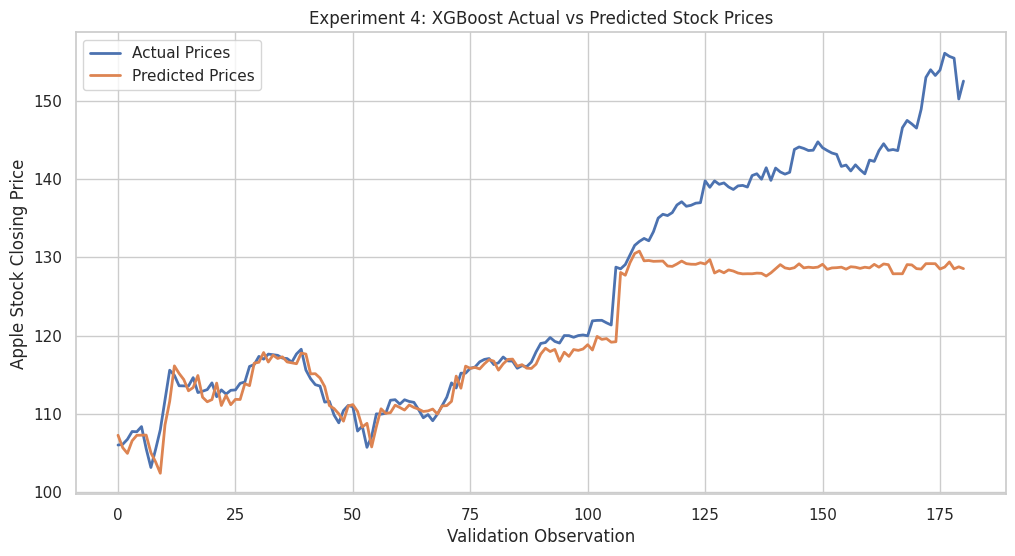

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    np.array(y_val),
    label="Actual Prices",
    linewidth=2
)

plt.plot(
    xgb_predictions,
    label="Predicted Prices",
    linewidth=2
)

plt.title("Experiment 4: XGBoost Actual vs Predicted Stock Prices")
plt.xlabel("Validation Observation")
plt.ylabel("Apple Stock Closing Price")
plt.legend()
plt.grid(True)
plt.show()

### Experiment 5: Support Vector Regression

This experiment applies Support Vector Regression (SVR) to predict Apple's next trading day's closing price. Unlike tree-based ensemble models, SVR uses support vector principles to identify a regression function that minimizes prediction errors while maintaining model complexity.

The experiment evaluates the effectiveness of SVR using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R². Its performance is compared against the previously evaluated regression algorithms.

In [ ]:
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Experiment 5: Support Vector Regression

svr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(
        kernel="rbf",
        C=10,
        epsilon=0.1,
        gamma="scale"
    ))
])

svr_model.fit(X_train, y_train)

print("SVR model trained successfully.")

SVR model trained successfully.


In [ ]:
svr_predictions = svr_model.predict(X_val)

svr_mae = mean_absolute_error(y_val, svr_predictions)
svr_rmse = np.sqrt(mean_squared_error(y_val, svr_predictions))
svr_r2 = r2_score(y_val, svr_predictions)

svr_results = pd.DataFrame({
    "Model": ["Support Vector Regression"],
    "MAE": [svr_mae],
    "RMSE": [svr_rmse],
    "R2": [svr_r2]
})

display(svr_results)

,Model,MAE,RMSE,R2
0,Support Vector Regression,8.567887,14.379602,0.023532


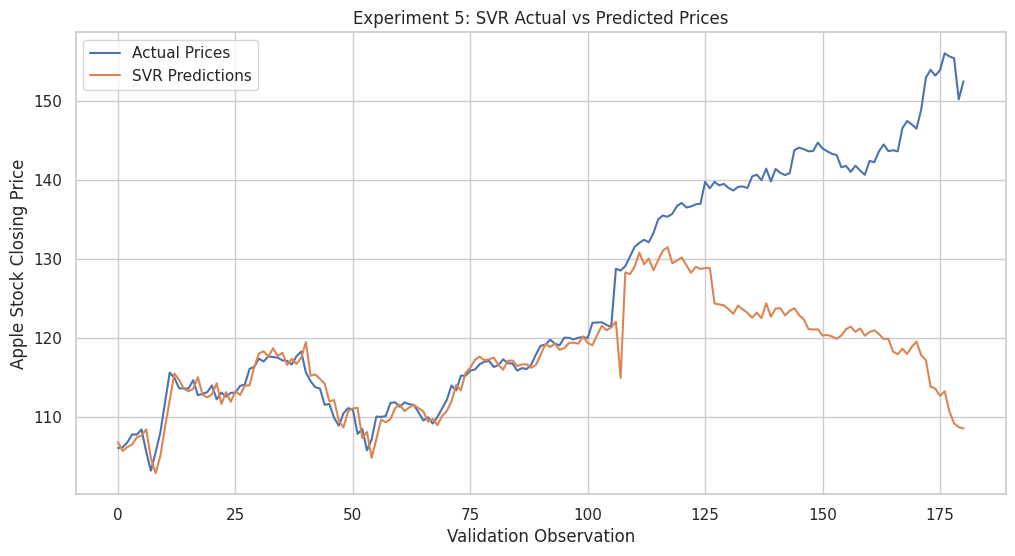

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(np.array(y_val), label="Actual Prices")
plt.plot(svr_predictions, label="SVR Predictions")

plt.title("Experiment 5: SVR Actual vs Predicted Prices")
plt.xlabel("Validation Observation")
plt.ylabel("Apple Stock Closing Price")
plt.legend()
plt.grid(True)
plt.show()

### Experiment 6: Hyperparameter-Tuned Support Vector Regression

This experiment aims to improve the predictive performance of Support Vector Regression through systematic hyperparameter optimization.

A Grid Search approach is used to evaluate different combinations of SVR parameters, including the regularization parameter (C), epsilon, kernel type, and gamma.

TimeSeriesSplit is employed during cross-validation to preserve the chronological order of observations and prevent future information from influencing earlier training periods.

The best-performing configuration is subsequently evaluated on the validation dataset using MAE, RMSE, and R².

In [ ]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

In [ ]:
# Experiment 6: Tuned SVR

svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR())
])

param_grid = [
    {
        "svr__kernel": ["linear"],
        "svr__C": [1, 10, 50, 100],
        "svr__epsilon": [0.01, 0.1, 0.5, 1]
    },
    {
        "svr__kernel": ["rbf"],
        "svr__C": [1, 10, 50, 100],
        "svr__epsilon": [0.01, 0.1, 0.5, 1],
        "svr__gamma": ["scale", 0.01, 0.1]
    }
]

tscv = TimeSeriesSplit(n_splits=5)

grid_search = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation MAE:", -grid_search.best_score_)

Fitting 5 folds for each of 64 candidates, totalling 320 fits
Best parameters: {'svr__C': 10, 'svr__epsilon': 0.5, 'svr__kernel': 'linear'}
Best cross-validation MAE: 1.165862267039351


In [ ]:
best_svr = grid_search.best_estimator_

tuned_svr_predictions = best_svr.predict(X_val)

tuned_svr_mae = mean_absolute_error(
    y_val, tuned_svr_predictions
)

tuned_svr_rmse = np.sqrt(
    mean_squared_error(y_val, tuned_svr_predictions)
)

tuned_svr_r2 = r2_score(
    y_val, tuned_svr_predictions
)

tuned_svr_results = pd.DataFrame({
    "Model": ["Tuned SVR"],
    "MAE": [tuned_svr_mae],
    "RMSE": [tuned_svr_rmse],
    "R2": [tuned_svr_r2]
})

display(tuned_svr_results)

,Model,MAE,RMSE,R2
0,Tuned SVR,0.913554,1.373652,0.991089


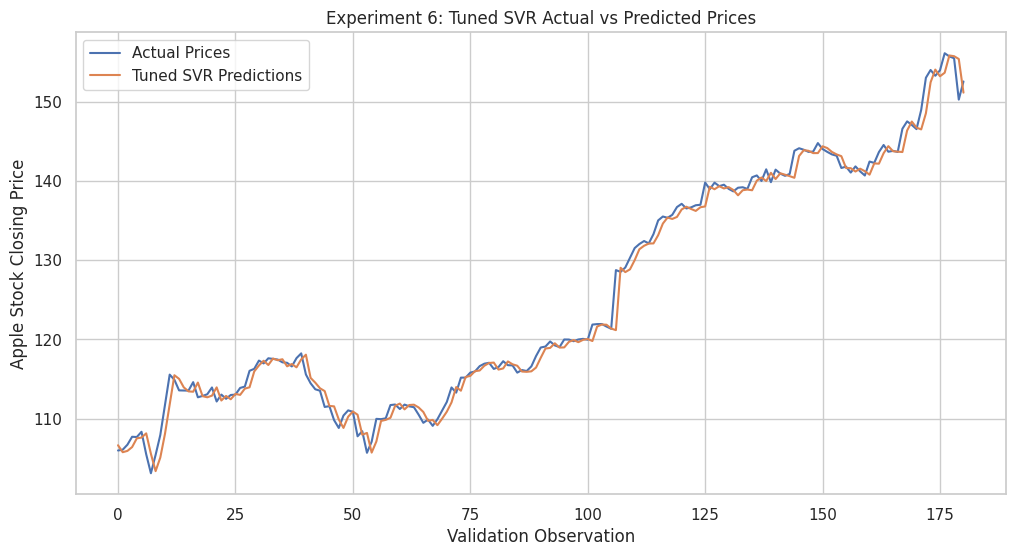

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    np.array(y_val),
    label="Actual Prices"
)

plt.plot(
    tuned_svr_predictions,
    label="Tuned SVR Predictions"
)

plt.title("Experiment 6: Tuned SVR Actual vs Predicted Prices")
plt.xlabel("Validation Observation")
plt.ylabel("Apple Stock Closing Price")
plt.legend()
plt.grid(True)
plt.show()

#### Model Validation: Naive Persistence Baseline and Directional Accuracy

Following the hyperparameter tuning of SVR, an additional evaluation was conducted to investigate whether its high predictive performance represented genuine forecasting ability or simply reflected the strong relationship between consecutive daily stock prices.

A naive persistence baseline was introduced, where the predicted next-day closing price is assumed to be equal to the current day's closing price.

Directional accuracy was also calculated to assess whether the model could correctly predict the direction of Apple's stock-price movement. These additional evaluations help establish whether the tuned SVR provides meaningful predictive information beyond simply carrying forward the latest observed price.

In [ ]:
# Naive Persistence Baseline

# Current day's closing price
current_close = X_val["close"].to_numpy()

# Predict tomorrow's closing price as today's closing price
naive_predictions = current_close

# Evaluate baseline
naive_mae = mean_absolute_error(y_val, naive_predictions)

naive_rmse = np.sqrt(
    mean_squared_error(y_val, naive_predictions)
)

naive_r2 = r2_score(y_val, naive_predictions)

naive_results = pd.DataFrame({
    "Model": ["Naive Persistence Baseline"],
    "MAE": [naive_mae],
    "RMSE": [naive_rmse],
    "R2": [naive_r2]
})

display(naive_results)

,Model,MAE,RMSE,R2
0,Naive Persistence Baseline,0.898287,1.355042,0.991329


In [ ]:
# Compare both models

validation_comparison = pd.DataFrame({
    "Model": [
        "Naive Persistence Baseline",
        "Tuned SVR"
    ],
    "MAE": [
        naive_mae,
        tuned_svr_mae
    ],
    "RMSE": [
        naive_rmse,
        tuned_svr_rmse
    ],
    "R2": [
        naive_r2,
        tuned_svr_r2
    ]
})

display(validation_comparison)

,Model,MAE,RMSE,R2
0,Naive Persistence Baseline,0.898287,1.355042,0.991329
1,Tuned SVR,0.913554,1.373652,0.991089


In [ ]:
# Actual and predicted price movements

actual_change = np.array(y_val) - current_close

predicted_change = (
    tuned_svr_predictions - current_close
)

# Directional accuracy
actual_direction = np.sign(actual_change)
predicted_direction = np.sign(predicted_change)

directional_accuracy = np.mean(
    actual_direction == predicted_direction
) * 100

print(
    f"SVR Directional Accuracy: "
    f"{directional_accuracy:.2f}%"
)

SVR Directional Accuracy: 49.17%


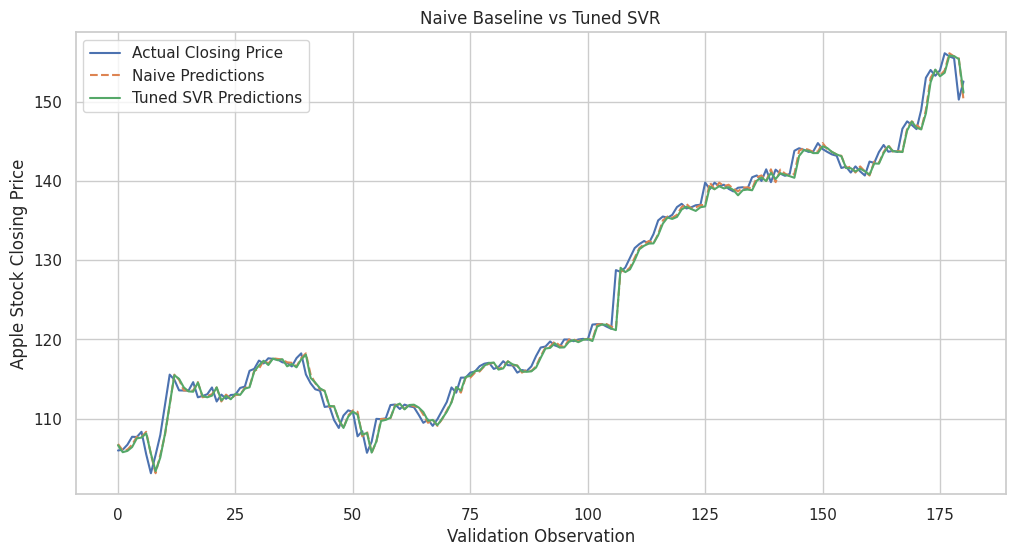

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    np.array(y_val),
    label="Actual Closing Price"
)

plt.plot(
    naive_predictions,
    label="Naive Predictions",
    linestyle="--"
)

plt.plot(
    tuned_svr_predictions,
    label="Tuned SVR Predictions"
)

plt.title("Naive Baseline vs Tuned SVR")
plt.xlabel("Validation Observation")
plt.ylabel("Apple Stock Closing Price")
plt.legend()
plt.grid(True)
plt.show()

### Experiment 7: Stock Return Prediction Using Percentage Changes

This experiment investigates whether transforming the prediction target from absolute stock prices into daily percentage returns can improve forecasting performance.

The previous experiments revealed that models predicting absolute closing prices could achieve high R² values without necessarily predicting future price movements accurately.

To address this limitation, the target variable is transformed into the percentage change between the current closing price and the next trading day's closing price.

The experiment evaluates whether predicting relative price movements provides a more meaningful assessment of forecasting ability. Performance is assessed using MAE, RMSE, R², and directional accuracy.

In [ ]:
# Calculate next-day percentage return

train_returns = (
    (y_train - X_train["close"])
    / X_train["close"]
) * 100

val_returns = (
    (y_val - X_val["close"])
    / X_val["close"]
) * 100

print("Training return statistics:")
display(train_returns.describe())

print("\nValidation return statistics:")
display(val_returns.describe())

Training return statistics:


,0
count,846.000000
mean,0.086228
std,1.540785
min,-7.992722
25%,-0.727362
50%,0.064524
75%,0.963259
max,8.198180



Validation return statistics:


,0
count,181.000000
mean,0.202897
std,1.089821
min,-3.357561
25%,-0.262403
50%,0.094057
75%,0.635084
max,6.098063


In [ ]:
def create_return_features(X):

    features = pd.DataFrame(index=X.index)

    features["open_change"] = (
        (X["open"] - X["close"]) / X["close"]
    )

    features["high_change"] = (
        (X["high"] - X["close"]) / X["close"]
    )

    features["low_change"] = (
        (X["low"] - X["close"]) / X["close"]
    )

    features["ma20_gap"] = (
        (X["close"] - X["MA_20"]) / X["close"]
    )

    features["ma50_gap"] = (
        (X["close"] - X["MA_50"]) / X["close"]
    )

    features["lag1_change"] = (
        (X["close"] - X["close_lag_1"])
        / X["close_lag_1"]
    )

    features["lag5_change"] = (
        (X["close"] - X["close_lag_5"])
        / X["close_lag_5"]
    )

    features["daily_return_pct"] = (
        X["daily_return_pct"]
    )

    features["rolling_volatility"] = (
        X["rolling_volatility"]
    )

    features["log_volume"] = np.log1p(X["volume"])

    return features


X_train_return = create_return_features(X_train)
X_val_return = create_return_features(X_val)

print("Training features:", X_train_return.shape)
print("Validation features:", X_val_return.shape)

Training features: (846, 10)
Validation features: (181, 10)


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

return_svr = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(
        kernel="rbf",
        C=10,
        epsilon=0.1,
        gamma="scale"
    ))
])

return_svr.fit(
    X_train_return,
    train_returns
)

return_predictions = return_svr.predict(
    X_val_return
)

print("Return-based SVR trained successfully.")

Return-based SVR trained successfully.


In [ ]:

return_mae = mean_absolute_error(
    val_returns,
    return_predictions
)

return_rmse = np.sqrt(
    mean_squared_error(val_returns, return_predictions)
)

return_r2 = r2_score(
    val_returns,
    return_predictions
)

return_directional_accuracy = np.mean(
    np.sign(val_returns) == np.sign(return_predictions)
) * 100

return_results = pd.DataFrame({
    "Model": ["Return-Based SVR"],
    "MAE": [return_mae],
    "RMSE": [return_rmse],
    "R2": [return_r2],
    "Directional Accuracy (%)": [
        return_directional_accuracy
    ]
})

display(return_results)

,Model,MAE,RMSE,R2,Directional Accuracy (%)
0,Return-Based SVR,0.834417,1.172598,-0.164111,48.618785


In [ ]:
zero_return_predictions = np.zeros(len(val_returns))

baseline_return_results = pd.DataFrame({
    "Model": ["Zero-Return Baseline"],
    "MAE": [
        mean_absolute_error(
            val_returns,
            zero_return_predictions
        )
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            val_returns,
            zero_return_predictions
        ))
    ],
    "R2": [
        r2_score(
            val_returns,
            zero_return_predictions
        )
    ]
})

display(baseline_return_results)

,Model,MAE,RMSE,R2
0,Zero-Return Baseline,0.730004,1.105583,-0.034854


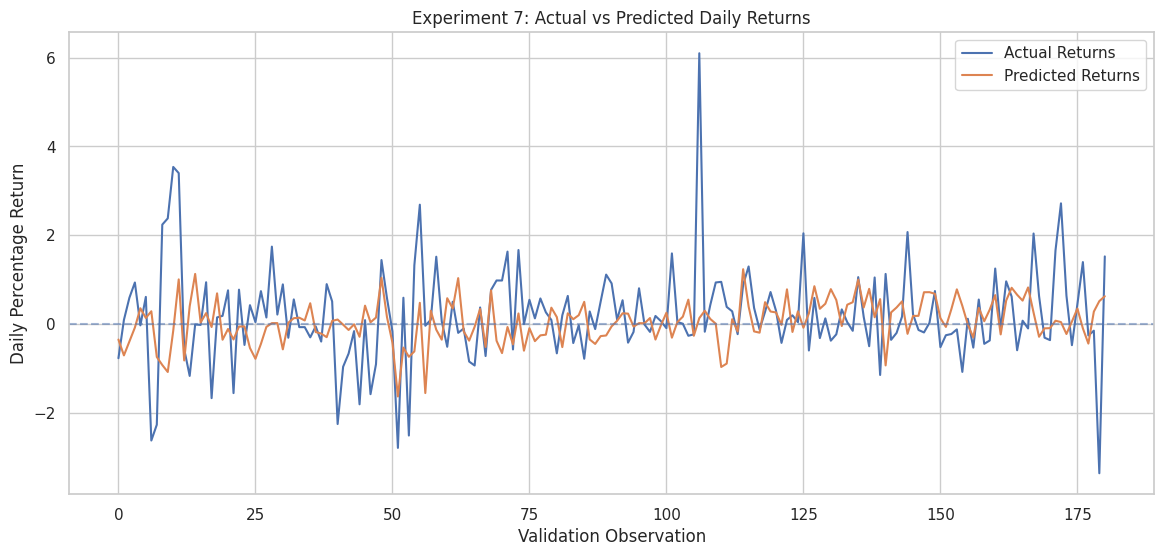

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    np.array(val_returns),
    label="Actual Returns"
)

plt.plot(
    return_predictions,
    label="Predicted Returns"
)

plt.axhline(0, linestyle="--", alpha=0.5)

plt.title("Experiment 7: Actual vs Predicted Daily Returns")
plt.xlabel("Validation Observation")
plt.ylabel("Daily Percentage Return")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import pandas as pd

# Convert actual and predicted values to arrays
actual_values = np.asarray(y_val).ravel()
naive_predictions = X_val["close"].to_numpy()
svr_predictions = np.asarray(tuned_svr_predictions).ravel()

# Confirm all arrays have equal lengths
print("Validation observations:", len(actual_values))
print("Naive predictions:", len(naive_predictions))
print("Tuned SVR predictions:", len(svr_predictions))

assert len(actual_values) == len(naive_predictions) == len(svr_predictions)

print("\nValidation alignment check passed.")

Validation observations: 181
Naive predictions: 181
Tuned SVR predictions: 181

Validation alignment check passed.


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

comparison = pd.DataFrame({
    "Model": ["Naive Persistence", "Tuned SVR"],
    "MAE": [
        mean_absolute_error(actual_values, naive_predictions),
        mean_absolute_error(actual_values, svr_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual_values, naive_predictions)),
        np.sqrt(mean_squared_error(actual_values, svr_predictions))
    ],
    "R2": [
        r2_score(actual_values, naive_predictions),
        r2_score(actual_values, svr_predictions)
    ]
})

print(comparison.round(4).to_string(index=False))

            Model    MAE   RMSE     R2
Naive Persistence 0.8983 1.3550 0.9913
        Tuned SVR 0.9136 1.3737 0.9911


In [ ]:
actual_direction = (actual_values > naive_predictions).astype(int)

naive_direction = np.zeros(len(actual_values), dtype=int)

svr_direction = (svr_predictions > naive_predictions).astype(int)

naive_accuracy = np.mean(naive_direction == actual_direction) * 100
svr_accuracy = np.mean(svr_direction == actual_direction) * 100

print(f"Naive baseline directional accuracy: {naive_accuracy:.2f}%")
print(f"Tuned SVR directional accuracy: {svr_accuracy:.2f}%")

Naive baseline directional accuracy: 44.20%
Tuned SVR directional accuracy: 49.17%


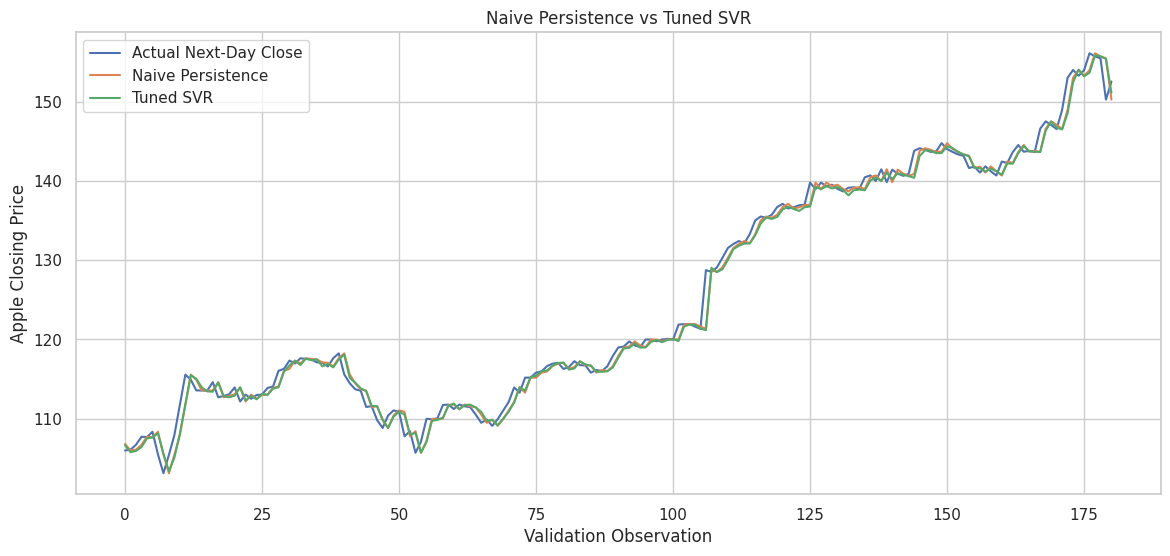

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(actual_values, label="Actual Next-Day Close")
plt.plot(naive_predictions, label="Naive Persistence")
plt.plot(svr_predictions, label="Tuned SVR")

plt.title("Naive Persistence vs Tuned SVR")
plt.xlabel("Validation Observation")
plt.ylabel("Apple Closing Price")
plt.legend()
plt.grid(True)
plt.show()

### Experiment 8: LSTM REGRESSION

This experiment introduces a Long Short-Term Memory (LSTM)
neural network to predict the next trading day's Apple closing
price.

Unlike traditional regression algorithms, LSTM networks are
designed to learn sequential relationships in time-series data.
The model will use a sequence of the previous 20 trading days
to forecast the next closing price.

The model will be trained using chronological training data
and evaluated on the same validation period used in previous
experiments. Feature and target scaling will be fitted using
training data only to prevent information leakage.

Performance will be evaluated using MAE, RMSE and R², with
the results compared against the naive persistence baseline
and previous regression experiments.

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select numeric input features
feature_columns = X_train.select_dtypes(include=[np.number]).columns.tolist()

assert "target_next_close" not in feature_columns, "Target leakage detected!"

X_train_lstm = X_train[feature_columns].copy()
X_val_lstm = X_val[feature_columns].copy()

# Confirm matching feature columns
X_val_lstm = X_val_lstm.reindex(columns=feature_columns)

# Convert targets to arrays
y_train_lstm = np.asarray(y_train).reshape(-1, 1)
y_val_lstm = np.asarray(y_val).reshape(-1, 1)

# Scale features using training data only
feature_scaler = StandardScaler()

X_train_scaled = feature_scaler.fit_transform(X_train_lstm)
X_val_scaled = feature_scaler.transform(X_val_lstm)

# Scale target using training data only
target_scaler = StandardScaler()

y_train_scaled = target_scaler.fit_transform(y_train_lstm)

# Define sequence length
LOOKBACK = 20

# Create training sequences
X_train_seq = []
y_train_seq = []

for i in range(LOOKBACK - 1, len(X_train_scaled)):
    X_train_seq.append(
        X_train_scaled[i - LOOKBACK + 1:i + 1]
    )
    y_train_seq.append(y_train_scaled[i])

X_train_seq = np.array(X_train_seq)
y_train_seq = np.array(y_train_seq)

# Create validation sequences using previous training observations
combined_scaled = np.vstack([
    X_train_scaled[-(LOOKBACK - 1):],
    X_val_scaled
])

X_val_seq = []

for i in range(len(X_val_scaled)):
    X_val_seq.append(
        combined_scaled[i:i + LOOKBACK]
    )

X_val_seq = np.array(X_val_seq)

# Display shapes
print("Training sequence shape:", X_train_seq.shape)
print("Training target shape:", y_train_seq.shape)
print("Validation sequence shape:", X_val_seq.shape)
print("Validation target shape:", y_val_lstm.shape)

Training sequence shape: (827, 20, 11)
Training target shape: (827, 1)
Validation sequence shape: (181, 20, 11)
Validation target shape: (181, 1)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)
np.random.seed(42)

model_lstm = Sequential([
    LSTM(
        64,
        return_sequences=True,
        input_shape=(LOOKBACK, X_train_seq.shape[2])
    ),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1)
])

model_lstm.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model_lstm.summary()

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_lstm = model_lstm.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(
        X_val_seq,
        target_scaler.transform(y_val_lstm)
    ),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    shuffle=False,
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 20, 64)         │        19,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,417 (126.63 KB)

 Trainable params: 32,417 (126.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - loss: 0.6914 - mae: 0.6284 - val_loss: 0.3868 - val_mae: 0.4795
Epoch 2/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.1402 - mae: 0.2937 - val_loss: 0.5845 - val_mae: 0.5870
Epoch 3/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.1511 - mae: 0.3029 - val_loss: 0.1668 - val_mae: 0.3482
Epoch 4/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0910 - mae: 0.2279 - val_loss: 0.5250 - val_mae: 0.5775
Epoch 5/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.1129 - mae: 0.2514 - val_loss: 0.1722 - val_mae: 0.3312
Epoch 6/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0587 - mae: 0.1917 - val_loss: 0.4613 - val_mae: 0.5533
Epoch 7/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.1051 - mae: 0.2478 - val_loss: 0.1538 - val_mae: 0.3109
Epoch 8/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0485 - mae: 0.1720 - val_loss: 0.3825 - val_mae: 0.5194
Epoch 9/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - lo

In [ ]:
# Generate predictions
lstm_predictions_scaled = model_lstm.predict(
    X_val_seq,
    verbose=0
)

# Convert predictions back to original price scale
lstm_predictions = target_scaler.inverse_transform(
    lstm_predictions_scaled
).ravel()

actual_values = y_val_lstm.ravel()

# Calculate metrics
lstm_mae = mean_absolute_error(actual_values, lstm_predictions)
lstm_rmse = np.sqrt(mean_squared_error(actual_values, lstm_predictions))
lstm_r2 = r2_score(actual_values, lstm_predictions)

print("LSTM REGRESSION RESULTS")
print("-----------------------")
print(f"MAE:  {lstm_mae:.4f}")
print(f"RMSE: {lstm_rmse:.4f}")
print(f"R²:   {lstm_r2:.4f}")

# Compare with naive baseline
print("\nNAIVE BASELINE COMPARISON")
print("------------------------")
print(f"Naive MAE:  {mean_absolute_error(actual_values, naive_predictions):.4f}")
print(f"Naive RMSE: {np.sqrt(mean_squared_error(actual_values, naive_predictions)):.4f}")
print(f"Naive R²:   {r2_score(actual_values, naive_predictions):.4f}")

LSTM REGRESSION RESULTS
-----------------------
MAE:  3.6287
RMSE: 4.9562
R²:   0.8840

NAIVE BASELINE COMPARISON
------------------------
Naive MAE:  0.8983
Naive RMSE: 1.3550
Naive R²:   0.9913


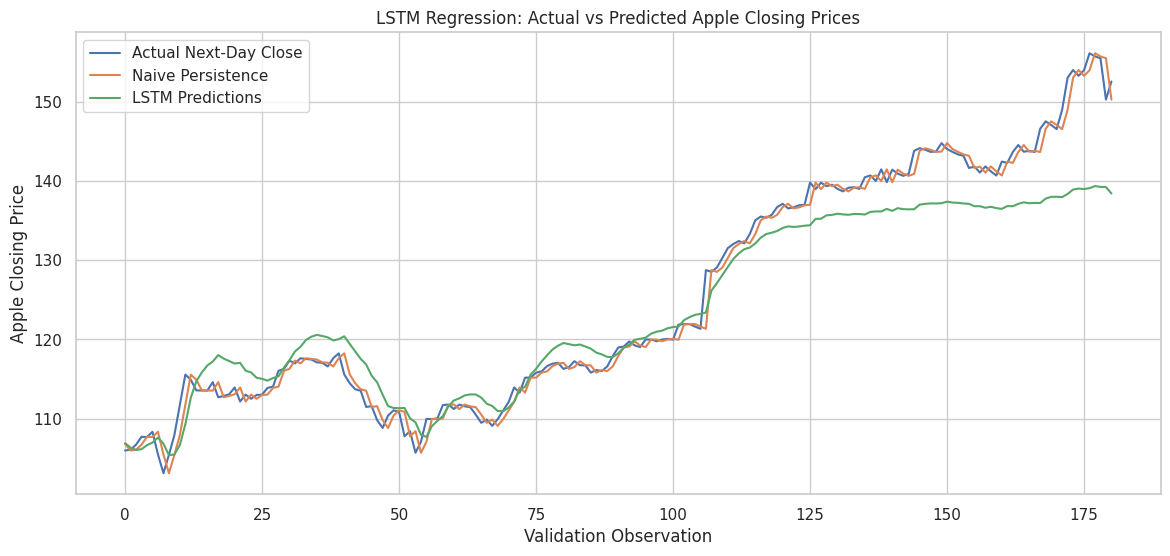

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(actual_values, label="Actual Next-Day Close")
plt.plot(naive_predictions, label="Naive Persistence")
plt.plot(lstm_predictions, label="LSTM Predictions")

plt.title("LSTM Regression: Actual vs Predicted Apple Closing Prices")
plt.xlabel("Validation Observation")
plt.ylabel("Apple Closing Price")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Compare training and validation target distributions

print("TRAINING VS VALIDATION PRICE RANGE")
print("=" * 50)

print("\nTRAINING TARGET")
print("Minimum:", y_train.min())
print("Maximum:", y_train.max())
print("Mean:", y_train.mean())

print("\nVALIDATION TARGET")
print("Minimum:", y_val.min())
print("Maximum:", y_val.max())
print("Mean:", y_val.mean())

# Count validation targets above the training maximum
above_training_max = (y_val > y_train.max()).sum()

print("\nVALIDATION TARGETS ABOVE TRAINING MAXIMUM")
print(above_training_max, "out of", len(y_val))

print(
    "Percentage:",
    round(above_training_max / len(y_val) * 100, 2),
    "%"
)

# Compare actual closing-price ranges
print("\nCURRENT CLOSE FEATURE")
print("Training maximum:", X_train["close"].max())
print("Validation maximum:", X_val["close"].max())

TRAINING VS VALIDATION PRICE RANGE

TRAINING TARGET
Minimum: 56.2542
Maximum: 133.0
Mean: 97.20456158392436

VALIDATION TARGET
Minimum: 103.13
Maximum: 156.1
Mean: 125.33798342541436

VALIDATION TARGETS ABOVE TRAINING MAXIMUM
67 out of 181
Percentage: 37.02 %

CURRENT CLOSE FEATURE
Training maximum: 133.0
Validation maximum: 156.1


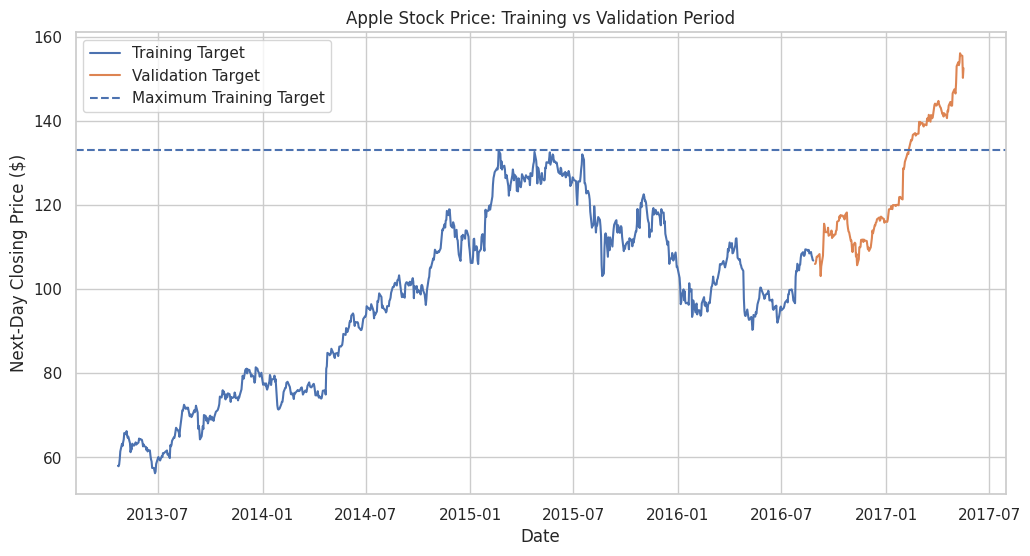

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    model_df.iloc[:train_end]["date"],
    y_train,
    label="Training Target"
)

plt.plot(
    model_df.iloc[train_end:validation_end]["date"],
    y_val,
    label="Validation Target"
)

plt.axhline(
    y_train.max(),
    linestyle="--",
    label="Maximum Training Target"
)

plt.title("Apple Stock Price: Training vs Validation Period")
plt.xlabel("Date")
plt.ylabel("Next-Day Closing Price ($)")
plt.legend()
plt.grid(True)
plt.show()

####Return Target Preparation

The next-day percentage return was calculated using the current closing price and the following trading day's closing price. This changes the prediction target from absolute stock prices to percentage price movements. Training and validation targets were prepared separately to preserve the chronological data split.

In [ ]:
# Calculate next-day percentage returns
train_returns = (
    (y_train - X_train["close"]) / X_train["close"]
) * 100

val_returns = (
    (y_val - X_val["close"]) / X_val["close"]
) * 100

# Check the targets
print("Training returns:")
print(train_returns.describe())

print("\nValidation returns:")
print(val_returns.describe())

# Check for invalid values
assert train_returns.notna().all()
assert val_returns.notna().all()
assert np.isfinite(train_returns).all()
assert np.isfinite(val_returns).all()

print("\nReturn targets created successfully.")

Training returns:
count    846.000000
mean       0.086228
std        1.540785
min       -7.992722
25%       -0.727362
50%        0.064524
75%        0.963259
max        8.198180
dtype: float64

Validation returns:
count    181.000000
mean       0.202897
std        1.089821
min       -3.357561
25%       -0.262403
50%        0.094057
75%        0.635084
max        6.098063
dtype: float64

Return targets created successfully.


#### Feature and Target Scaling

StandardScaler was applied to the input features and percentage-return targets. The scalers were fitted exclusively on training data and then applied to validation data to prevent data leakage.

In [ ]:
# Scale input features
feature_scaler_return = StandardScaler()

X_train_scaled_return = feature_scaler_return.fit_transform(X_train)
X_val_scaled_return = feature_scaler_return.transform(X_val)

# Scale return targets
return_scaler = StandardScaler()

y_train_scaled_return = return_scaler.fit_transform(
    np.asarray(train_returns).reshape(-1, 1)
)

y_val_scaled_return = return_scaler.transform(
    np.asarray(val_returns).reshape(-1, 1)
)

print("Training feature shape:", X_train_scaled_return.shape)
print("Validation feature shape:", X_val_scaled_return.shape)
print("Training target shape:", y_train_scaled_return.shape)
print("Validation target shape:", y_val_scaled_return.shape)

print("\nTraining target mean:", y_train_scaled_return.mean())
print("Training target standard deviation:", y_train_scaled_return.std())

Training feature shape: (846, 11)
Validation feature shape: (181, 11)
Training target shape: (846, 1)
Validation target shape: (181, 1)

Training target mean: 2.519655091347873e-17
Training target standard deviation: 0.9999999999999999


#### LSTM Sequence Preparation

Input data was arranged into sequences of 20 consecutive trading days. The final 19 training observations were included when constructing validation sequences to preserve continuity without mixing training and validation targets.

In [ ]:
# Define sequence length
LOOKBACK = 20

# Create training sequences
X_train_seq_return = []
y_train_seq_return = []

for i in range(LOOKBACK - 1, len(X_train_scaled_return)):
    X_train_seq_return.append(
        X_train_scaled_return[i - LOOKBACK + 1:i + 1]
    )
    y_train_seq_return.append(
        y_train_scaled_return[i]
    )

X_train_seq_return = np.array(X_train_seq_return)
y_train_seq_return = np.array(y_train_seq_return)

# Include previous 19 training observations for validation
combined_scaled_return = np.vstack([
    X_train_scaled_return[-(LOOKBACK - 1):],
    X_val_scaled_return
])

X_val_seq_return = []

for i in range(len(X_val_scaled_return)):
    X_val_seq_return.append(
        combined_scaled_return[i:i + LOOKBACK]
    )

X_val_seq_return = np.array(X_val_seq_return)

# Check sequence dimensions
print("Training sequences:", X_train_seq_return.shape)
print("Training targets:", y_train_seq_return.shape)
print("Validation sequences:", X_val_seq_return.shape)
print("Validation targets:", y_val_scaled_return.shape)

# Verify alignment
assert len(X_train_seq_return) == len(y_train_seq_return)
assert len(X_val_seq_return) == len(y_val_scaled_return)
assert X_train_seq_return.shape[1] == LOOKBACK
assert X_val_seq_return.shape[1] == LOOKBACK

print("\nSequence alignment checks passed.")

Training sequences: (827, 20, 11)
Training targets: (827, 1)
Validation sequences: (181, 20, 11)
Validation targets: (181, 1)

Sequence alignment checks passed.


### Experiment 9 Return-Based LSTM Model Training

A Sequential LSTM model with two LSTM layers, dropout regularization and a dense output layer was trained to predict next-day percentage returns. Adam optimization, MSE loss and early stopping were used to control training and reduce overfitting.

In [ ]:
# Build the return-based LSTM
model_lstm_return = Sequential([
    LSTM(
        64,
        return_sequences=True,
        input_shape=(LOOKBACK, X_train_seq_return.shape[2])
    ),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

# Compile model
model_lstm_return.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Early stopping
early_stopping_return = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train model
history_lstm_return = model_lstm_return.fit(
    X_train_seq_return,
    y_train_seq_return,
    validation_data=(X_val_seq_return, y_val_scaled_return),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping_return],
    shuffle=False,
    verbose=1
)

print("\nReturn-based LSTM training completed.")
print("Epochs trained:", len(history_lstm_return.history["loss"]))

Epoch 1/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - loss: 1.0061 - mae: 0.7233 - val_loss: 0.5968 - val_mae: 0.5336
Epoch 2/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 1.0166 - mae: 0.7337 - val_loss: 0.5277 - val_mae: 0.4779
Epoch 3/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.9900 - mae: 0.7169 - val_loss: 0.5564 - val_mae: 0.4991
Epoch 4/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.9950 - mae: 0.7188 - val_loss: 0.5279 - val_mae: 0.4793
Epoch 5/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.9864 - mae: 0.7144 - val_loss: 0.5439 - val_mae: 0.4894
Epoch 6/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.9826 - mae: 0.7141 - val_loss: 0.5393 - val_mae: 0.4858
Epoch 7/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.9825 - mae: 0.7141 - val_loss: 0.5638 - val_mae: 0.5051
Epoch 8/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.9753 - mae: 0.7148 - val_loss: 0.5833 - val_mae: 0.5227
Epoch 9/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - lo

####  Model Evaluation

Predicted percentage returns were converted back into next-day closing prices. The model was evaluated using MAE, RMSE, R² and directional accuracy. Its performance was also compared with the naive persistence baseline, which assumes the next closing price will equal the current closing price.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict scaled returns
predicted_returns_scaled = model_lstm_return.predict(
    X_val_seq_return
)

# Convert predictions back to percentage returns
predicted_returns = return_scaler.inverse_transform(
    predicted_returns_scaled
).flatten()

actual_returns = np.asarray(val_returns)

# Convert predicted returns into closing prices
current_prices = X_val["close"].to_numpy()

predicted_prices = current_prices * (
    1 + predicted_returns / 100
)

actual_prices = np.asarray(y_val)

# Evaluate predicted prices
mae = mean_absolute_error(actual_prices, predicted_prices)
rmse = np.sqrt(mean_squared_error(actual_prices, predicted_prices))
r2 = r2_score(actual_prices, predicted_prices)

# Evaluate directional accuracy
directional_accuracy = np.mean(
    np.sign(actual_returns) == np.sign(predicted_returns)
) * 100

print("RETURN-BASED LSTM RESULTS")
print("-------------------------")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")
print(f"Directional Accuracy: {directional_accuracy:.2f}%")

# Compare with naive persistence baseline
baseline_mae = mean_absolute_error(actual_prices, current_prices)
baseline_rmse = np.sqrt(mean_squared_error(actual_prices, current_prices))
baseline_r2 = r2_score(actual_prices, current_prices)

print("\nNAIVE PERSISTENCE BASELINE")
print("--------------------------")
print(f"MAE: {baseline_mae:.4f}")
print(f"RMSE: {baseline_rmse:.4f}")
print(f"R²: {baseline_r2:.4f}")

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
RETURN-BASED LSTM RESULTS
-------------------------
MAE: 0.9058
RMSE: 1.3741
R²: 0.9911
Directional Accuracy: 50.28%

NAIVE PERSISTENCE BASELINE
--------------------------
MAE: 0.8983
RMSE: 1.3550
R²: 0.9913


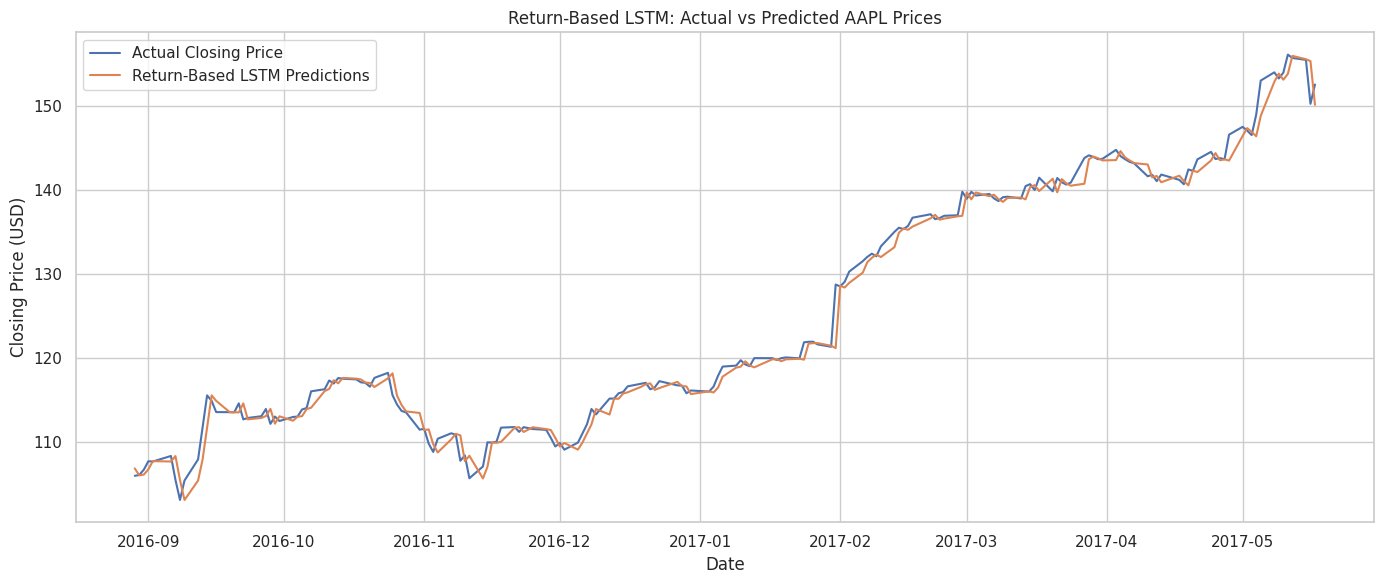

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    model_df.loc[X_val.index, "date"],
    actual_prices,
    label="Actual Closing Price"
)

plt.plot(
    model_df.loc[X_val.index, "date"],
    predicted_prices,
    label="Return-Based LSTM Predictions"
)

plt.title("Return-Based LSTM: Actual vs Predicted AAPL Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

####Predicted Return Diagnostics

The distribution of predicted returns was examined and compared with actual returns. A zero-return baseline was also evaluated to determine whether the LSTM learned useful return patterns or mainly predicted small changes around zero.

In [ ]:
# Inspect predicted return distribution
print("PREDICTED RETURNS")
print(pd.Series(predicted_returns).describe())

print("\nACTUAL RETURNS")
print(pd.Series(actual_returns).describe())

# Compare predicted returns with zero-return baseline
zero_return_mae = mean_absolute_error(
    actual_returns,
    np.zeros_like(actual_returns)
)

zero_return_rmse = np.sqrt(
    mean_squared_error(
        actual_returns,
        np.zeros_like(actual_returns)
    )
)

print("\nRETURN-BASED COMPARISON")
print(f"LSTM Return MAE: {mean_absolute_error(actual_returns, predicted_returns):.4f}")
print(f"Zero Return MAE: {zero_return_mae:.4f}")
print(f"LSTM Return RMSE: {np.sqrt(mean_squared_error(actual_returns, predicted_returns)):.4f}")
print(f"Zero Return RMSE: {zero_return_rmse:.4f}")

print("\nPrediction standard deviation:", np.std(predicted_returns))
print("Actual return standard deviation:", np.std(actual_returns))

PREDICTED RETURNS
count    181.000000
mean      -0.054837
std        0.047785
min       -0.133756
25%       -0.097185
50%       -0.060419
75%       -0.010598
max        0.058304
dtype: float64

ACTUAL RETURNS
count    181.000000
mean       0.202897
std        1.089821
min       -3.357561
25%       -0.262403
50%        0.094057
75%        0.635084
max        6.098063
dtype: float64

RETURN-BASED COMPARISON
LSTM Return MAE: 0.7359
Zero Return MAE: 0.7300
LSTM Return RMSE: 1.1186
Zero Return RMSE: 1.1056

Prediction standard deviation: 0.047653124
Actual return standard deviation: 1.0868060314407564


### Experiment 10 Classification Target Preparation

Next-day stock returns were converted into binary labels. Positive returns were assigned 1, while zero or negative returns were assigned 0. This enabled the LSTM to predict price direction rather than exact prices or returns.

In [ ]:
# Create binary direction targets
train_direction = (train_returns > 0).astype(int)
val_direction = (val_returns > 0).astype(int)

# Align training labels with 20-day sequences
y_train_direction = train_direction.iloc[LOOKBACK - 1:].to_numpy()

# Validation sequences already have matching context
y_val_direction = val_direction.to_numpy()

# Check class distribution
print("Training class distribution:")
print(pd.Series(y_train_direction).value_counts().sort_index())

print("\nValidation class distribution:")
print(pd.Series(y_val_direction).value_counts().sort_index())

# Verify alignment
assert len(y_train_direction) == len(X_train_seq_return)
assert len(y_val_direction) == len(X_val_seq_return)

print("\nClassification targets aligned successfully.")

Training class distribution:
0    403
1    424
Name: count, dtype: int64

Validation class distribution:
0     80
1    101
Name: count, dtype: int64

Classification targets aligned successfully.


#### LSTM Classification Model

A Sequential LSTM model was trained to classify next-day stock price direction. A sigmoid output layer and binary cross-entropy loss were used. Early stopping monitored validation loss to limit overfitting.

In [ ]:
# Build classification model
model_lstm_classification = Sequential([
    LSTM(
        64,
        return_sequences=True,
        input_shape=(LOOKBACK, X_train_seq_return.shape[2])
    ),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

# Compile model
model_lstm_classification.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early stopping
early_stopping_classification = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train model
history_lstm_classification = model_lstm_classification.fit(
    X_train_seq_return,
    y_train_direction,
    validation_data=(X_val_seq_return, y_val_direction),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping_classification],
    shuffle=False,
    verbose=1
)

print("\nClassification LSTM training completed.")
print("Epochs trained:", len(history_lstm_classification.history["loss"]))

Epoch 1/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 18s 73ms/step - accuracy: 0.5212 - loss: 0.6907 - val_accuracy: 0.4420 - val_loss: 0.7370
Epoch 2/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.5526 - loss: 0.6910 - val_accuracy: 0.4420 - val_loss: 0.7121
Epoch 3/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.5756 - loss: 0.6860 - val_accuracy: 0.4420 - val_loss: 0.7275
Epoch 4/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 0.5780 - loss: 0.6845 - val_accuracy: 0.4309 - val_loss: 0.7208
Epoch 5/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.5611 - loss: 0.6802 - val_accuracy: 0.4420 - val_loss: 0.7394
Epoch 6/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.5550 - loss: 0.6845 - val_accuracy: 0.4254 - val_loss: 0.7153
Epoch 7/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.5792 - loss: 0.6785 - val_accuracy: 0.4420 - val_loss: 0.7359
Epoch 8/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.5719 - loss: 0.6811 - val_accuracy: 0

####Model Evaluation

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Generate prediction probabilities
y_val_prob = model_lstm_classification.predict(
    X_val_seq_return
).flatten()

# Convert probabilities into binary predictions
y_val_pred = (y_val_prob >= 0.5).astype(int)

# Calculate classification metrics
print("LSTM CLASSIFICATION RESULTS")
print("----------------------------")
print(f"Accuracy: {accuracy_score(y_val_direction, y_val_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val_direction, y_val_pred):.4f}")
print(f"Precision: {precision_score(y_val_direction, y_val_pred, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_val_direction, y_val_pred, zero_division=0):.4f}")
print(f"F1 Score: {f1_score(y_val_direction, y_val_pred, zero_division=0):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_val_direction, y_val_prob):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val_direction,
    y_val_pred,
    zero_division=0
))

# Majority-class baseline
majority_class = pd.Series(y_train_direction).mode()[0]

baseline_predictions = np.full(
    len(y_val_direction),
    majority_class
)

print("\nMAJORITY-CLASS BASELINE")
print("-----------------------")
print(f"Baseline class: {majority_class}")
print(f"Baseline accuracy: {accuracy_score(y_val_direction, baseline_predictions):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_direction, y_val_pred))

6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 450ms/step
LSTM CLASSIFICATION RESULTS
----------------------------
Accuracy: 0.4420
Balanced Accuracy: 0.5000
Precision: 0.0000
Recall: 0.0000
F1 Score: 0.0000
ROC-AUC: 0.4921

Classification Report:
              precision    recall  f1-score   support

           0       0.44      1.00      0.61        80
           1       0.00      0.00      0.00       101

    accuracy                           0.44       181
   macro avg       0.22      0.50      0.31       181
weighted avg       0.20      0.44      0.27       181


MAJORITY-CLASS BASELINE
-----------------------
Baseline class: 1
Baseline accuracy: 0.5580

Confusion Matrix:
[[ 80   0]
 [101   0]]


### 11 Saving the Best Model

The selected Tuned SVR model was saved to Google Drive using Joblib. The saved pipeline includes both feature standardization and the trained SVR estimator, allowing the complete model to be reloaded for future predictions.

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Import required libraries
import os
import joblib

# Create model storage folder
model_folder = "/content/drive/MyDrive/AAPL_Stock_Forecasting/models"
os.makedirs(model_folder, exist_ok=True)

# Save the fitted Tuned SVR pipeline
model_path = os.path.join(
    model_folder,
    "best_tuned_svr_model.pkl"
)

joblib.dump(best_svr, model_path)

print("Best model saved successfully!")
print("Location:", model_path)

# Verify saved model
loaded_model = joblib.load(model_path)

print("\nModel loaded successfully!")
print("Model type:", type(loaded_model).__name__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Best model saved successfully!
Location: /content/drive/MyDrive/AAPL_Stock_Forecasting/models/best_tuned_svr_model.pkl

Model loaded successfully!
Model type: Pipeline
